# Entrega N°1 - Proyecto Final

Para este proyecto seleccionamos el dataset *"Estimation of Obesity Levels Based on Eating Habits and Physical Condition"*, publicado en el repositorio UCI. Reúne 2.111 registros de personas de Colombia, México y Perú, con 17 variables sobre sus datos físicos, hábitos de alimentación, actividad física y antecedentes familiares. Cada persona está clasificada en uno de siete niveles de peso, desde peso insuficiente hasta obesidad tipo III.

### Importar el Dataset del repositorio de UCI

In [9]:
# pip install ucimlrepo

# fetch dataset 
estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition = fetch_ucirepo(id=544) 
  
# data (as pandas dataframes) 
X = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.features 
y = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.targets 


### Librerías

In [61]:
# !pip install -q imbalanced-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy import stats
from sklearn.model_selection import train_test_split

# Apariencia de tablas y gráficas
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)

# Semilla para que todos obtengamos los mismos resultados
SEMILLA = 20
np.random.seed(SEMILLA)

print("pandas", pd.__version__, "| seaborn", sns.__version__)

pandas 3.0.6 | seaborn 0.13.2


### Visualización de los datos

In [11]:
dataset = pd.concat([X, y], axis=1)
print("Dimensiones:", dataset.shape)
dataset.head()

Dimensiones: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.000,1.620,64.000,yes,no,2.000,3.000,Sometimes,no,2.000,no,0.000,1.000,no,Public_Transportation,Normal_Weight
1,Female,21.000,1.520,56.000,yes,no,3.000,3.000,Sometimes,yes,3.000,yes,3.000,0.000,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.000,1.800,77.000,yes,no,2.000,3.000,Sometimes,no,2.000,no,2.000,1.000,Frequently,Public_Transportation,Normal_Weight
3,Male,27.000,1.800,87.000,no,no,3.000,3.000,Sometimes,no,2.000,no,2.000,0.000,Frequently,Walking,Overweight_Level_I
4,Male,22.000,1.780,89.800,no,no,2.000,1.000,Sometimes,no,2.000,no,0.000,0.000,Sometimes,Public_Transportation,Overweight_Level_II


In [12]:
def resumen(df):
    # Ficha técnica por columna: tipo, nulos, cardinalidad y un ejemplo
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "no_nulos": df.notna().sum(),
        "nulos": df.isna().sum(),
        "%_nulos": (df.isna().mean() * 100).round(2),
        "valores_unicos": df.nunique(),
        "ejemplo": df.iloc[0],
    })

In [13]:
resumen(dataset)

,tipo,no_nulos,nulos,%_nulos,valores_unicos,ejemplo
Gender,str,2111,0,0.000,2,Female
Age,float64,2111,0,0.000,1402,21.000
Height,float64,2111,0,0.000,1574,1.620
Weight,float64,2111,0,0.000,1525,64.000
family_history_with_overweight,str,2111,0,0.000,2,yes
FAVC,str,2111,0,0.000,2,no
FCVC,float64,2111,0,0.000,810,2.000
NCP,float64,2111,0,0.000,635,3.000
CAEC,str,2111,0,0.000,4,Sometimes
SMOKE,str,2111,0,0.000,2,no


**¿Qué representa cada característica?** 

- *Hábitos de alimentación*

| Variable | Descripción | Valores |
|:---:|:---:|:---:|
| `FAVC` | Consumo frecuente de alimentos calóricos | Sí / No |
| `FCVC` | Consumo de verduras en las comidas | Nunca / A veces / Siempre |
| `NCP` | Comidas principales al día | Entre 1 y 2 / Tres / Más de tres |
| `CAEC` | Consumo de alimentos entre comidas | No / A veces / Frecuentemente / Siempre |
| `CH2O` | Consumo diario de agua | Menos de 1 L / Entre 1 y 2 L / Más de 2 L |
| `CALC` | Consumo de alcohol | No bebo / A veces / Frecuentemente / Siempre |

- *Condición física y estilo de vida*

| Variable | Descripción | Valores |
|:---:|:---:|:---:|
| `SMOKE` | Fuma | Sí / No |
| `SCC` | Controla las calorías que consume | Sí / No |
| `FAF` | Frecuencia de actividad física | No hago / 1–2 días / 2–4 días / 4–5 días por semana |
| `TUE` | Tiempo diario frente a dispositivos electrónicos | 0–2 h / 3–5 h / Más de 5 h |
| `MTRANS` | Medio de transporte habitual | Automóvil / Moto / Bicicleta / Transporte público / Caminar |

### Revisión de duplicados y valores fuera del rango

In [ ]:
# Registros duplicadas
n_dup = dataset.duplicated().sum()
print(f"\nRegistros duplicadas: {n_dup} ({n_dup / len(dataset):.1%} del total)")

# Ver cuáles son (keep=False muestra todas las copias, no solo las repetidas)
duplicados = dataset[dataset.duplicated(keep=False)]
print(f"Registros involucrados (originales + copias): {len(duplicados)}")
print("\nClase de los duplicados:")
print(dataset[dataset.duplicated()]["NObeyesdad"].value_counts())

# Valores fuera de rango (coherencia con la encuesta)
rangos = {"Age": (10, 100), "Height": (1.20, 2.20), "Weight": (30, 250),   # rangos fisiológicamente plausibles
          "FCVC": (1, 3), "NCP": (1, 4), "CH2O": (1, 3), "FAF": (0, 3), "TUE": (0, 2)}
print("\nValores fuera del rango esperado:")
for col, (mn, mx) in rangos.items():
    fuera = ((dataset[col] < mn) | (dataset[col] > mx)).sum()
    print(f"  {col:7s} rango [{mn}, {mx}] -> {fuera} fuera de rango")
    
# Categorías incorrectas en las variables de texto
print("\nCategorías de las variables de texto:")
for col in dataset.select_dtypes(include=["object", "string"]).columns:
    print(f"  {col:32s} {sorted(dataset[col].unique().tolist())}")


Registros duplicadas: 24 (1.1% del total)
Registros involucrados (originales + copias): 33

Clase de los duplicados:
NObeyesdad
Overweight_Level_I     14
Insufficient_Weight     5
Normal_Weight           5
Name: count, dtype: int64

Valores fuera del rango esperado:
  Age     rango [10, 100] -> 0 fuera de rango
  Height  rango [1.2, 2.2] -> 0 fuera de rango
  Weight  rango [30, 250] -> 0 fuera de rango
  FCVC    rango [1, 3] -> 0 fuera de rango
  NCP     rango [1, 4] -> 0 fuera de rango
  CH2O    rango [1, 3] -> 0 fuera de rango
  FAF     rango [0, 3] -> 0 fuera de rango
  TUE     rango [0, 2] -> 0 fuera de rango

Categorías de las variables de texto:
  Gender                           ['Female', 'Male']
  family_history_with_overweight   ['no', 'yes']
  FAVC                             ['no', 'yes']
  CAEC                             ['Always', 'Frequently', 'Sometimes', 'no']
  SMOKE                            ['no', 'yes']
  SCC                              ['no', 'yes']
  CALC    

### Validación de relación entre IMC y Target

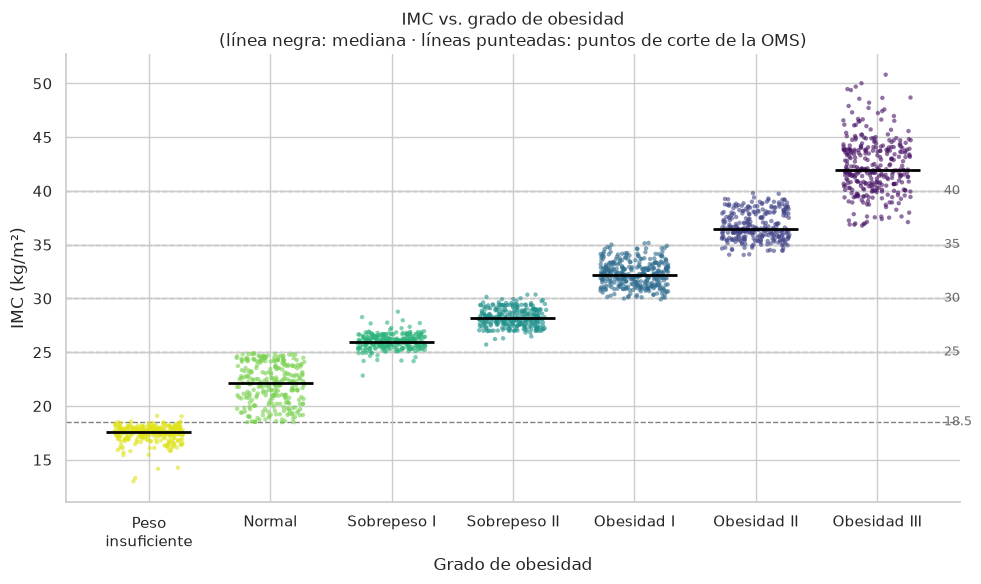

In [14]:
dataset['IMC'] = dataset['Weight'] / dataset['Height']**2

orden = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II',
         'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
etiquetas = ['Peso\ninsuficiente', 'Normal', 'Sobrepeso I', 'Sobrepeso II',
             'Obesidad I', 'Obesidad II', 'Obesidad III']
colores = plt.cm.viridis_r(np.linspace(0.05, 0.95, 7))

fig, ax = plt.subplots(figsize=(10, 6))
rng = np.random.default_rng(0)
for i, (clase, color) in enumerate(zip(orden, colores)):
    imc = dataset.loc[dataset['NObeyesdad'] == clase, 'IMC']
    x = i + rng.uniform(-0.28, 0.28, len(imc))   # dispersión horizontal para que no se encimen
    ax.scatter(x, imc, s=10, color=color, alpha=0.6, edgecolor='none')
    ax.hlines(imc.median(), i - 0.35, i + 0.35, color='black', linewidth=2)   # mediana

# Puntos de corte de la OMS
for v in [18.5, 25, 30, 35, 40]:
    ax.axhline(v, color='gray', linestyle='--', linewidth=1, zorder=0)
    ax.text(6.55, v, f'{v}', va='center', fontsize=9, color='dimgray')

ax.set_xticks(range(7), etiquetas)
ax.set_xlabel('Grado de obesidad')
ax.set_ylabel('IMC (kg/m²)')
ax.set_title('IMC vs. grado de obesidad\n(línea negra: mediana · líneas punteadas: puntos de corte de la OMS)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### Válidación de balance de clases

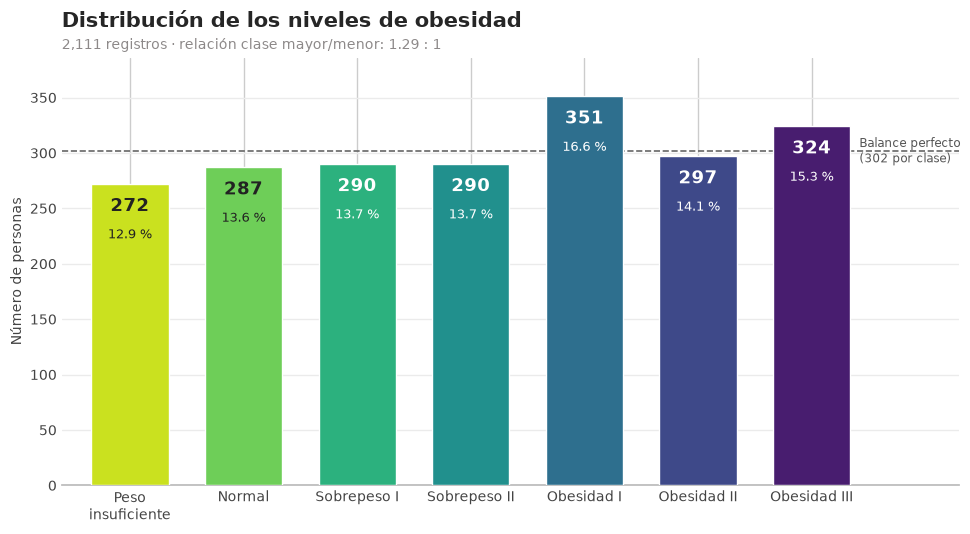

In [30]:
import numpy as np
import matplotlib.pyplot as plt

orden = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II',
         'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
etiquetas = ['Peso\ninsuficiente', 'Normal', 'Sobrepeso I', 'Sobrepeso II',
             'Obesidad I', 'Obesidad II', 'Obesidad III']
conteo = dataset['NObeyesdad'].value_counts().reindex(orden)
porcentaje = conteo / len(dataset) * 100

# Paleta ordenada: de amarillo-verde (peso bajo) a morado (obesidad III)
colores = plt.cm.viridis_r(np.linspace(0.08, 0.92, len(orden)))

fig, ax = plt.subplots(figsize=(10, 5.5))
barras = ax.bar(etiquetas, conteo.values, color=colores, width=0.68, zorder=3)

# Número y porcentaje dentro de cada barra
for barra, n, p, c in zip(barras, conteo.values, porcentaje.values, colores):
    x = barra.get_x() + barra.get_width() / 2
    lum = 0.299*c[0] + 0.587*c[1] + 0.114*c[2]
    texto = '#222222' if lum > 0.55 else 'white'      # texto oscuro en barras claras
    ax.text(x, n - 12, f'{n}', ha='center', va='top', fontsize=13, fontweight='bold', color=texto, zorder=5)
    ax.text(x, n - 40, f'{p:.1f} %', ha='center', va='top', fontsize=9.5, color=texto, zorder=5)

# Línea de balance perfecto (queda detrás de las barras)
ideal = len(dataset) / len(orden)
ax.axhline(ideal, color='#666666', linestyle='--', linewidth=1.2, zorder=2)
ax.text(6.42, ideal, f'Balance perfecto\n({ideal:.0f} por clase)', va='center', fontsize=8.5, color='#555555')

ax.set_title('Distribución de los niveles de obesidad', fontsize=15, fontweight='bold', loc='left', pad=22)
ax.text(0, 1.02, f'{len(dataset):,} registros · relación clase mayor/menor: {conteo.max()/conteo.min():.2f} : 1',
        transform=ax.transAxes, fontsize=10, color="#8D8989")
ax.set_ylabel('Número de personas', fontsize=10, color='#444444')
ax.set_ylim(0, conteo.max() * 1.1)
ax.set_xlim(-0.6, 7.3)
ax.grid(axis='y', color = '#ebebeb', zorder=0)
ax.tick_params(axis='both', length=0, labelsize=10, colors='#444444')
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color('#bbbbbb')
plt.tight_layout()
plt.show()

El dataset está balanceado. La clase más grande (Obesidad I) tiene apenas 1,29 veces los registros de la más pequeña (Peso insuficiente). Todas quedan cerca del 14,3 % que tendría un balance perfecto, que es la línea punteada de la gráfica.

### Análisis univariado de las variables númericas

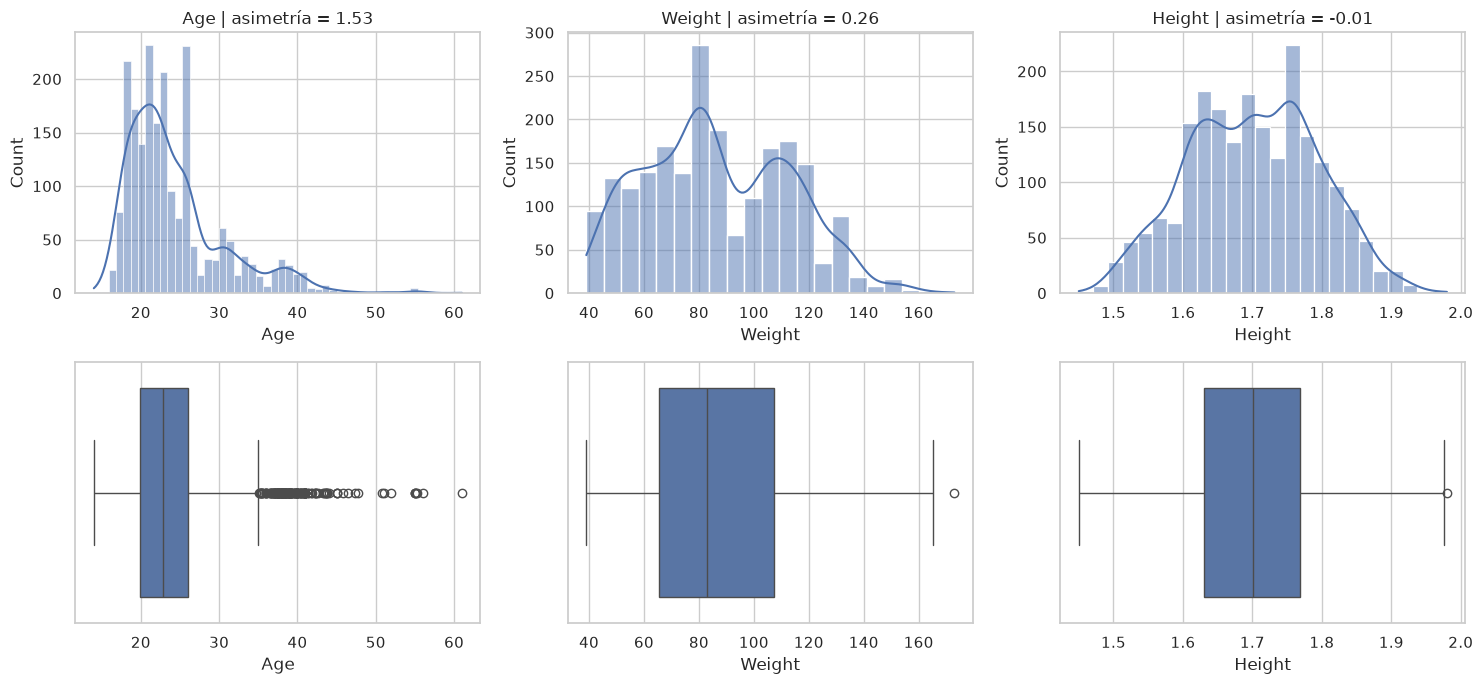

In [22]:
numericas = ["Age", "Weight", "Height"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, col in enumerate(numericas):
    sns.histplot(dataset[col], kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"{col} | asimetría = {dataset[col].skew():.2f}")
    sns.boxplot(x=dataset[col], ax=axes[1, i])
plt.tight_layout(); plt.show()

#### Observaciones

- *Age* tiene asimetría positiva fuerte (1,53). La mayoría de los encuestados son jóvenes: el 76 % tiene 26 años o menos y la mediana es 22,8. La cola se extiende hasta 61 años. El boxplot marca 168 valores atípicos, todos por encima de unos 35 años. No son errores: son personas mayores que simplemente son pocas en la muestra, así que no hay que eliminarlas. Para el informe, esto significa que los resultados representan sobre todo a población joven.
- *Weight* es casi simétrica (0,26), pero tiene varios picos. Eso tiene sentido, porque mezcla personas de 7 niveles de peso distintos. Solo hay un atípico, de 173 kg, y es un valor plausible.
- *Height* es prácticamente normal (−0,01), con una forma de campana centrada en 1,70 m y sin atípicos relevantes.

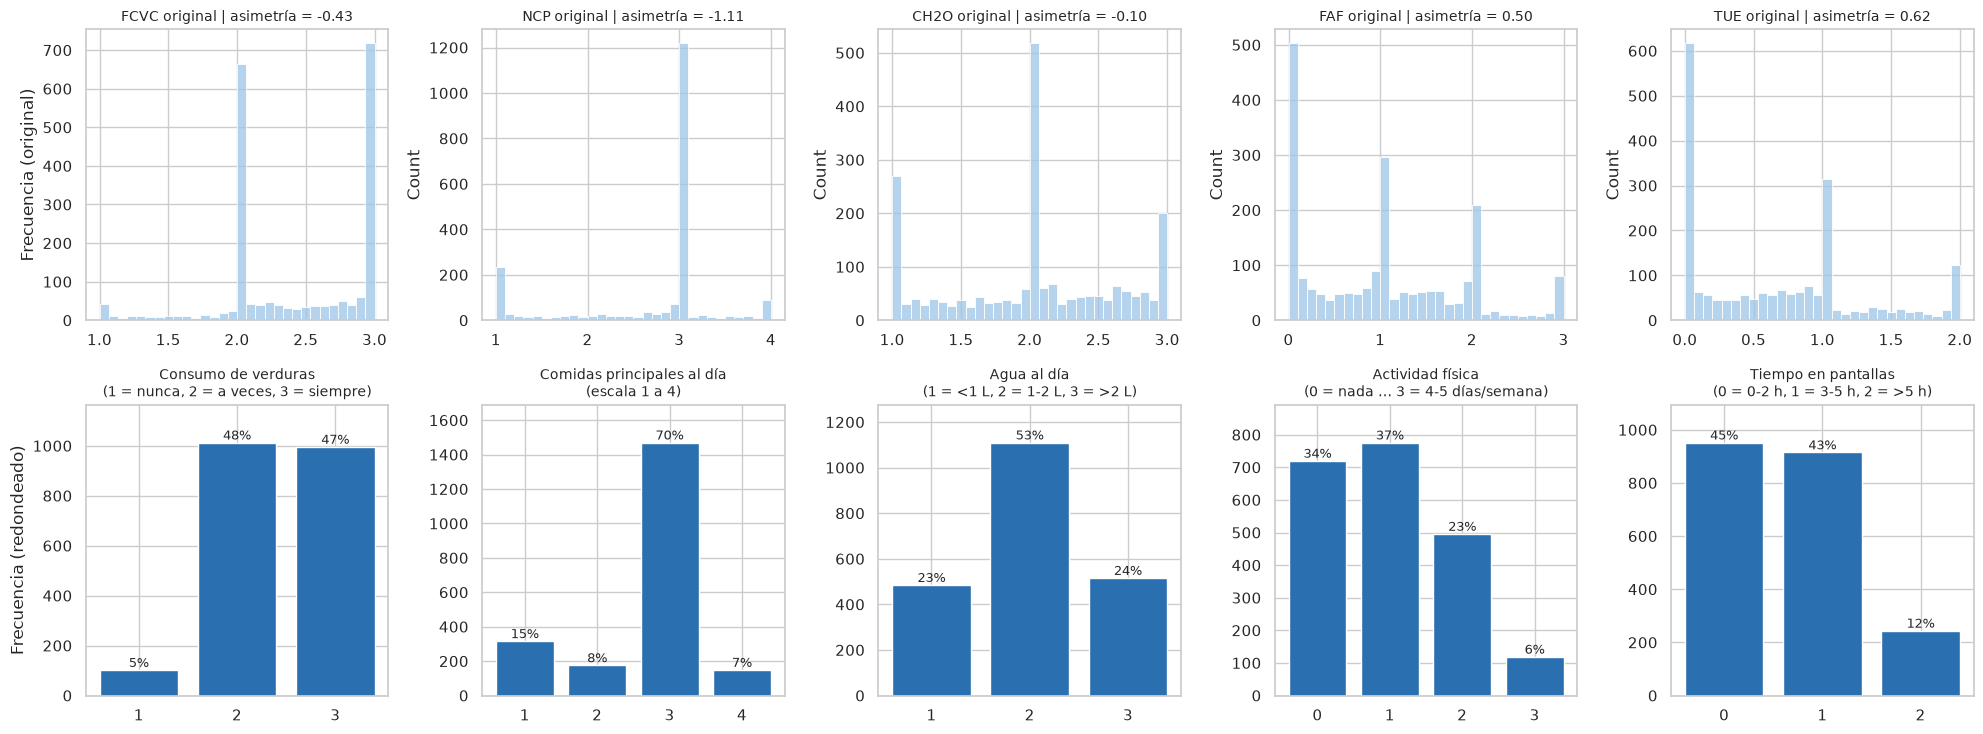

In [ ]:
ordinales = {
    "FCVC": "Consumo de verduras\n(1 = nunca, 2 = a veces, 3 = siempre)",
    "NCP":  "Comidas principales al día\n(escala 1 a 4)",
    "CH2O": "Agua al día\n(1 = <1 L, 2 = 1-2 L, 3 = >2 L)",
    "FAF":  "Actividad física\n(0 = nada … 3 = 4-5 días/semana)",
    "TUE":  "Tiempo en pantallas\n(0 = 0-2 h, 1 = 3-5 h, 2 = >5 h)",
}

fig, axes = plt.subplots(2, 5, figsize=(20, 7.5))
for i, (col, titulo) in enumerate(ordinales.items()):
    # Fila 1: valores originales (con decimales sintéticos)
    sns.histplot(dataset[col], bins=30, ax=axes[0, i], color='#9ec5e8')
    axes[0, i].set_title(f"{col} original | asimetría = {dataset[col].skew():.2f}", fontsize=10)
    axes[0, i].set_xlabel('')

    # Fila 2: valores redondeados a la escala de la encuesta
    conteo = dataset[col].round().astype(int).value_counts().sort_index()
    barras = axes[1, i].bar(conteo.index.astype(str), conteo.values, color='#2a6fb0')
    axes[1, i].bar_label(barras, labels=[f'{v/len(dataset):.0%}' for v in conteo.values], fontsize=9)
    axes[1, i].set_title(titulo, fontsize=10)
    axes[1, i].set_ylim(0, conteo.max() * 1.15)

axes[0, 0].set_ylabel('Frecuencia (original)')
axes[1, 0].set_ylabel('Frecuencia (redondeado)')
plt.tight_layout(); plt.show()


#### Observaciones

- *FCVC, verduras*: casi nadie dice “nunca” (5 %). El resto se reparte entre “a veces” (48 %) y “siempre” (47 %).
NCP, comidas al día: la gran mayoría responde 3 (70 %). Es la variable menos variada, así que probablemente aporte poco para distinguir clases.
- *CH2O, agua*: la distribución es la más equilibrada. La mitad toma entre 1 y 2 litros (53 %).
- *FAF, actividad física*: el 34 % no hace nada de ejercicio y solo el 6 % hace 4 o 5 días por semana. Puede ser de las variables más útiles para el modelo.
- *TUE, pantallas*: la mayoría pasa 0–2 h (45 %) o 3–5 h (43 %) frente a pantallas, y solo el 12 % más de 5 h.


### Análisis bivariado

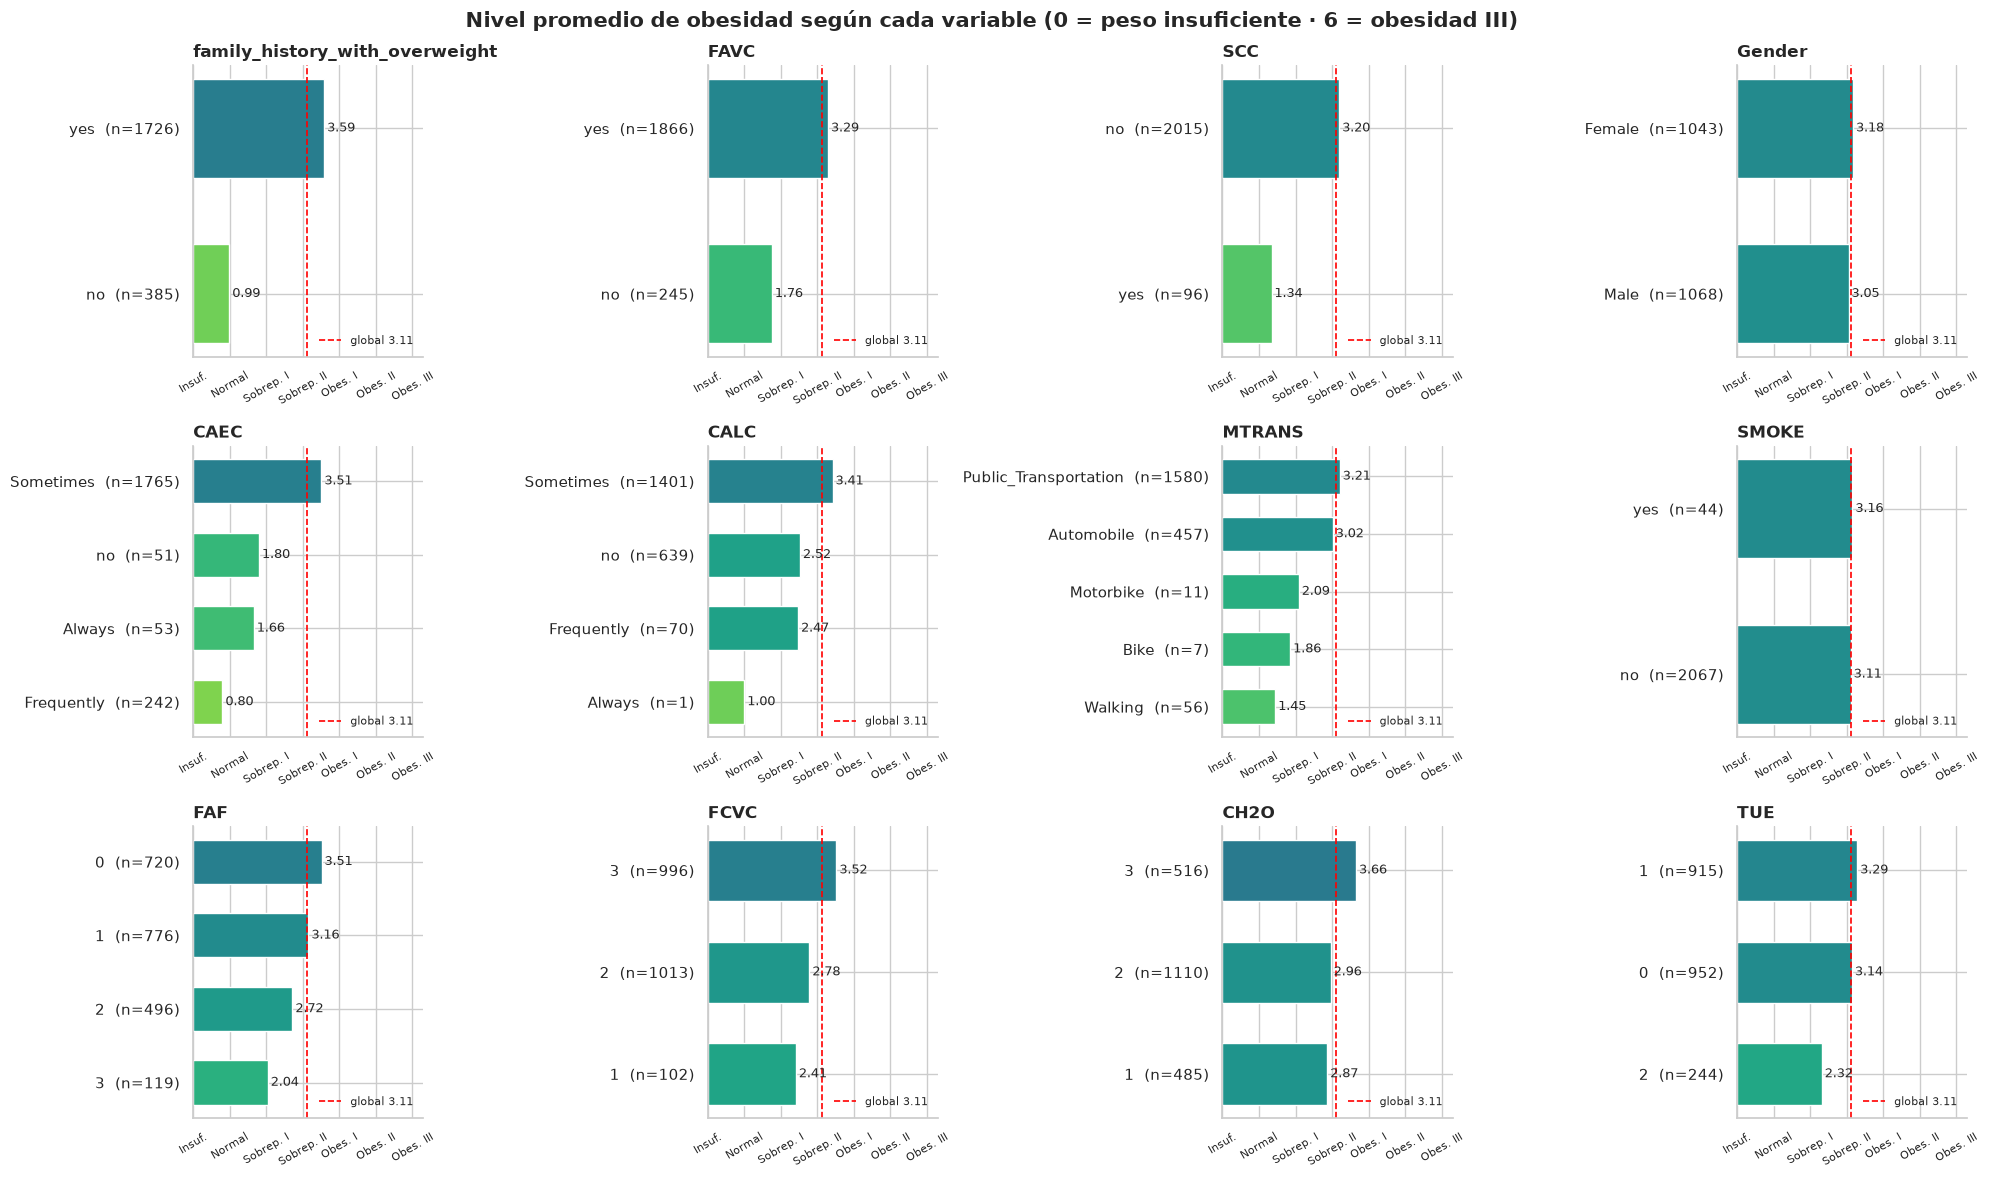

In [24]:
import matplotlib.pyplot as plt

# Codificación ordinal del objetivo: 0 = peso insuficiente ... 6 = obesidad III
niveles = {'Insufficient_Weight': 0, 'Normal_Weight': 1, 'Overweight_Level_I': 2,
           'Overweight_Level_II': 3, 'Obesity_Type_I': 4, 'Obesity_Type_II': 5, 'Obesity_Type_III': 6}
nombres_cortos = ['Insuf.', 'Normal', 'Sobrep. I', 'Sobrep. II', 'Obes. I', 'Obes. II', 'Obes. III']
dataset["nivel"] = dataset["NObeyesdad"].map(niveles)
nivel_global = dataset["nivel"].mean()

dataset_biv = dataset.copy()
for col in ["FCVC", "NCP", "CH2O", "FAF", "TUE"]:
    dataset_biv[col] = dataset_biv[col].round().astype(int)

variables = ["family_history_with_overweight", "FAVC", "SCC", "Gender",
             "CAEC", "CALC", "MTRANS", "SMOKE",
             "FAF", "FCVC", "CH2O", "TUE"]
cmap = plt.cm.viridis_r

fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, col in zip(axes.ravel(), variables):
    grupo = dataset_biv.groupby(col)["nivel"].agg(["mean", "size"]).sort_values("mean")
    etiquetas = [f"{c}  (n={n})" for c, n in zip(grupo.index.astype(str), grupo["size"])]
    colores = cmap(0.08 + 0.84 * grupo["mean"].values / 6)   # el color refleja el nivel promedio
    ax.barh(etiquetas, grupo["mean"].values, color=colores, height=0.6)
    for y, v in enumerate(grupo["mean"].values):
        ax.text(v + 0.08, y, f"{v:.2f}", va="center", fontsize=9)
    ax.axvline(nivel_global, color="red", ls="--", lw=1.2, label=f"global {nivel_global:.2f}")
    ax.set_xlim(0, 6.3)
    ax.set_xticks(range(7), nombres_cortos, fontsize=8, rotation=30)
    ax.set_title(col, fontsize=12, fontweight="bold", loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower right", fontsize=8, frameon=False)

fig.suptitle("Nivel promedio de obesidad según cada variable (0 = peso insuficiente · 6 = obesidad III)",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### V de Cramer

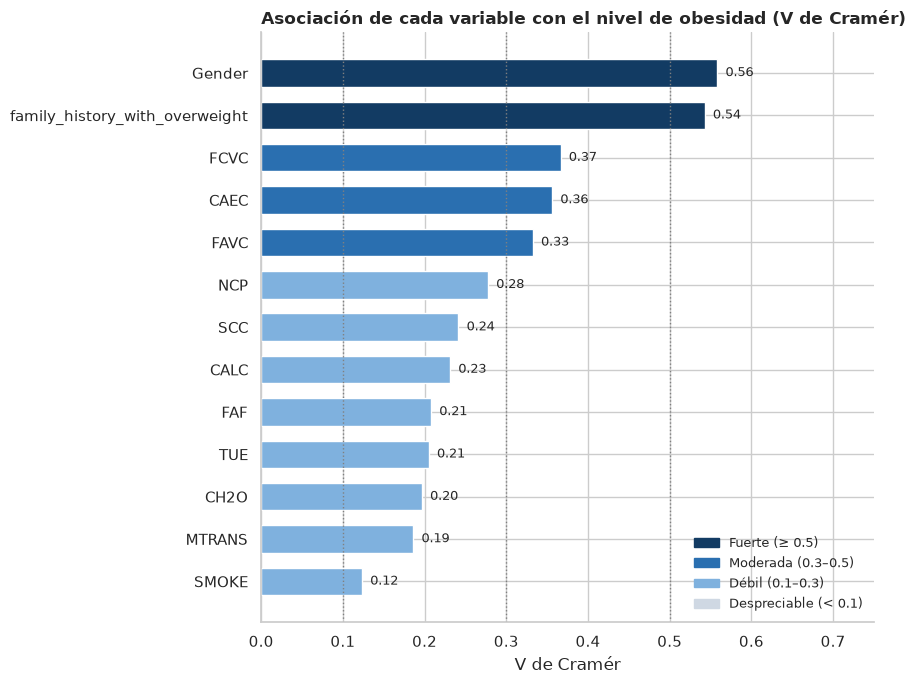

In [34]:
def v_cramer(x, y):
    tabla = pd.crosstab(x, y)
    chi2, p = chi2_contingency(tabla, correction=False)[:2]
    n = tabla.values.sum()
    r, k = tabla.shape
    return np.sqrt((chi2 / n) / (min(r, k) - 1)), p

# Ordinales numéricas redondeadas a su escala
dataset_cat = dataset.copy()
for col in ["FCVC", "NCP", "CH2O", "FAF", "TUE"]:
    dataset_cat[col] = dataset_cat[col].round().astype(int)

cat_vars = [c for c in dataset_cat.select_dtypes(include=["object", "string"]).columns if c != "NObeyesdad"] \
           + ["FCVC", "NCP", "CH2O", "FAF", "TUE"]

resultados = pd.DataFrame(
    [v_cramer(dataset_cat[c], dataset_cat["NObeyesdad"]) for c in cat_vars],
    index=cat_vars, columns=["V de Cramér", "p-valor"]
).sort_values("V de Cramér")

# Gráfica coloreada por fuerza de asociación
def fuerza(v):
    return "Fuerte" if v >= 0.5 else "Moderada" if v >= 0.3 else "Débil" if v >= 0.1 else "Despreciable"
colores_fuerza = {"Fuerte": "#123b63", "Moderada": "#2a6fb0", "Débil": "#7fb1de", "Despreciable": "#cfd8e3"}
colores = [colores_fuerza[fuerza(v)] for v in resultados["V de Cramér"]]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(resultados.index, resultados["V de Cramér"], color=colores, height=0.65)
for y, v in enumerate(resultados["V de Cramér"]):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=9)
for umbral in [0.1, 0.3, 0.5]:
    ax.axvline(umbral, color="gray", ls=":", lw=1)
ax.set_xlim(0, 0.75)
ax.set_xlabel("V de Cramér")
ax.set_title("Asociación de cada variable con el nivel de obesidad (V de Cramér)", loc="left", fontweight="bold")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in colores_fuerza.values()],
          ["Fuerte (≥ 0.5)", "Moderada (0.3–0.5)", "Débil (0.1–0.3)", "Despreciable (< 0.1)"],
          loc="lower right", frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### Matriz de Spearman para Variables Numéricas

In [65]:
# Target: codificación ordinal de 0 a 6 (peso insuficiente … obesidad III)
niveles = {
    "Insufficient_Weight": 0,
    "Normal_Weight": 1,
    "Overweight_Level_I": 2,
    "Overweight_Level_II": 3,
    "Obesity_Type_I": 4,
    "Obesity_Type_II": 5,
    "Obesity_Type_III": 6,
}

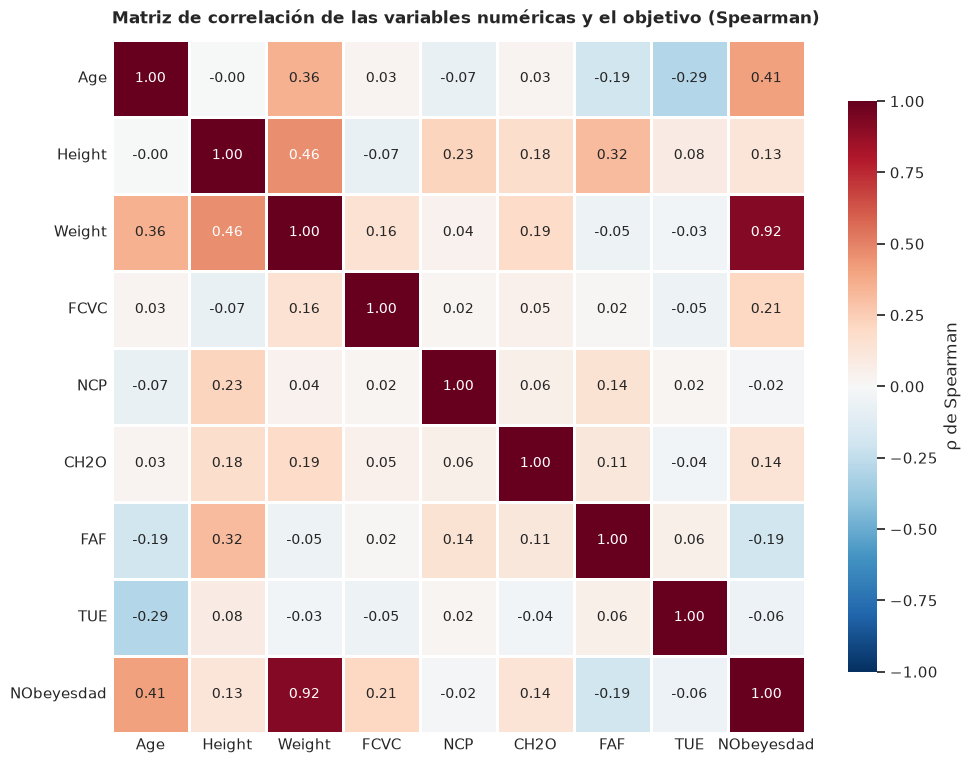

In [68]:
numericas = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE", "NObeyesdad"]
corr = data[numericas].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            square=True, linewidths=1, linecolor="white", annot_kws={"size": 10},
            cbar_kws={"shrink": 0.8, "label": "ρ de Spearman"}, ax=ax)

ax.set_title("Matriz de correlación de las variables numéricas y el objetivo (Spearman)",
             loc="left", fontweight="bold", fontsize=12, pad=12)
ax.tick_params(length=0)
plt.xticks(rotation=0); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

### Codificación de variables categóricas de entrada

In [57]:
data = dataset.copy()

# Binarias
data["Gender"] = data["Gender"].map({"Female": 0, "Male": 1})
for col in ["family_history_with_overweight", "FAVC", "SMOKE", "SCC"]:
    data[col] = data[col].map({"no": 0, "yes": 1})

# Ordinales
for col in ["FCVC", "NCP", "CH2O", "FAF", "TUE", "IMC"]:
    data[col] = data[col].round().astype(int)

orden_frecuencia = {"no": 0, "Sometimes": 1, "Frequently": 2, "Always": 3}
data["CAEC"] = data["CAEC"].map(orden_frecuencia)
data["CALC"] = data["CALC"].replace("Always", "Frequently")   # "Always" tiene 1 solo registro
data["CALC"] = data["CALC"].map(orden_frecuencia)

# Nominales
data["MTRANS"] = data["MTRANS"].replace({"Bike": "Two_Wheels", "Motorbike": "Two_Wheels"})  # 7 y 11 casos
data = pd.get_dummies(data, columns=["MTRANS"], prefix="MTRANS", dtype=int)

# Target: codificación ordinal de 0 a 6 (peso insuficiente … obesidad III)
niveles = {
    "Insufficient_Weight": 0,
    "Normal_Weight": 1,
    "Overweight_Level_I": 2,
    "Overweight_Level_II": 3,
    "Obesity_Type_I": 4,
    "Obesity_Type_II": 5,
    "Obesity_Type_III": 6,
}
data["NObeyesdad"] = data["NObeyesdad"].map(niveles)
nombres_clases = {v: k for k, v in niveles.items()}   # para volver a nombres al mostrar resultados

# Verificación de la transformación
print(f"Dimensiones: {data.shape}")
print(f"Nulos totales: {data.isna().sum().sum()}")
print(f"Columnas no numéricas: {data.select_dtypes(exclude='number').columns.tolist()}")
print("\nValores únicos por columna (excepto continuas):")
for col in data.columns.drop(["Age", "Height", "Weight"]):
    print(f"  {col:32s} {sorted(data[col].unique().tolist())}")

data.head()

Dimensiones: (2111, 22)
Nulos totales: 0
Columnas no numéricas: []

Valores únicos por columna (excepto continuas):
  Gender                           [0, 1]
  family_history_with_overweight   [0, 1]
  FAVC                             [0, 1]
  FCVC                             [1, 2, 3]
  NCP                              [1, 2, 3, 4]
  CAEC                             [0, 1, 2, 3]
  SMOKE                            [0, 1]
  CH2O                             [1, 2, 3]
  SCC                              [0, 1]
  FAF                              [0, 1, 2, 3]
  TUE                              [0, 1, 2]
  CALC                             [0, 1, 2]
  NObeyesdad                       [0, 1, 2, 3, 4, 5, 6]
  IMC                              [13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51]
  nivel                            [0, 1, 2, 3, 4, 5, 6]
  MTRANS_Automobile                [0, 1]
  

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,NObeyesdad,IMC,nivel,MTRANS_Automobile,MTRANS_Public_Transportation,MTRANS_Two_Wheels,MTRANS_Walking
0,0,21.000,1.620,64.000,1,0,2,3,1,0,2,0,0,1,0,1,24,1,0,1,0,0
1,0,21.000,1.520,56.000,1,0,3,3,1,1,3,1,3,0,1,1,24,1,0,1,0,0
2,1,23.000,1.800,77.000,1,0,2,3,1,0,2,0,2,1,2,1,24,1,0,1,0,0
3,1,27.000,1.800,87.000,0,0,3,3,1,0,2,0,2,0,2,2,27,2,0,0,0,1
4,1,22.000,1.780,89.800,0,0,2,1,1,0,2,0,0,0,1,3,28,3,0,1,0,0


### División del Dataset Train / Test

Se eliminan los duplicados y se dividen los datos 80/20 estratificado. Se arman dos conjuntos de variables con las mismas filas: **preventivo** (solo hábitos, sin peso, estatura ni IMC) y **operativo** (todas las variables más IMC, como referencia).

In [ ]:
# Duplicados: se eliminan ANTES de dividir, para que una misma persona no quede en entrenamiento y en prueba
sin_dup = ~dataset.duplicated()
print(f"Duplicados eliminados: {(~sin_dup).sum()} ({len(dataset)} -> {sin_dup.sum()} registros)")
data_u = data[sin_dup]

# Nunca son variables de entrada: el target y 'nivel' (copia numérica del target, creada para graficar)
excluir = ["NObeyesdad", "nivel"]

# Benchmark preventivo (principal): solo hábitos y antecedentes. Sin Weight, Height ni IMC (se calcula con ellos)
X_prev = data_u.drop(columns=excluir + ["Weight", "Height", "IMC"])
# Benchmark operativo (referencia): todas las variables + IMC, para medir el efecto de la fuga
X_oper = data_u.drop(columns=excluir)
y = data_u["NObeyesdad"]

# Un único split para ambos benchmarks (mismas filas, misma semilla)
idx_train, idx_test = train_test_split(
    y.index, test_size=0.2, stratify=y, random_state=SEMILLA)

X_train, X_test = X_prev.loc[idx_train], X_prev.loc[idx_test]               # preventivo
X_train_oper, X_test_oper = X_oper.loc[idx_train], X_oper.loc[idx_test]     # operativo
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

# Verificación anti-fuga
assert not {"NObeyesdad", "nivel", "Weight", "Height", "IMC"} & set(X_train.columns), "Fuga en el preventivo"
assert not {"NObeyesdad", "nivel"} & set(X_train_oper.columns), "El target está en las variables de entrada"

print("\nPreventivo -> Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Operativo  -> Entrenamiento:", X_train_oper.shape, "| Prueba:", X_test_oper.shape)

# Proporción de cada clase en total, entrenamiento y prueba
proporciones = pd.DataFrame({
    "Total (%)": y.value_counts(normalize=True),
    "Entrenamiento (%)": y_train.value_counts(normalize=True),
    "Prueba (%)": y_test.value_counts(normalize=True),
}).sort_index()
proporciones.index = proporciones.index.map(nombres_clases)
print((proporciones * 100).round(1))